<a href="https://colab.research.google.com/github/anmoldadhich02/EDA/blob/main/EDA_Assessments_Penguins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis

**Dataset:** Palmer Penguins (`penguins_size.csv`)  
**Source:** https://raw.githubusercontent.com/salemprakash/EDA/main/Data/penguins_size.csv



## Setup — Load the penguins dataset

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/penguins_size.csv"
penguins = pd.read_csv(DATA_URL, na_values=["NA", "N/A", ""])

# Use the same working DataFrame throughout the notebook.
df = penguins.copy()

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())
df.info()

Dataset shape: (344, 7)

Columns: ['species', 'island', 'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             343 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  341 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## Assessment 1 — Data frames, joins, and normalization

In [ ]:
print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Shape:", df.shape)
print("\nSummary:")
display(df.describe(include="all"))

# Demonstrate row binding by splitting the data into two parts.
split_point = len(df) // 2
df_part1 = df.iloc[:split_point].copy()
df_part2 = df.iloc[split_point:].copy()
appended_df = pd.concat([df_part1, df_part2], ignore_index=True)
print("\nAppending two row subsets:", appended_df.shape)

# Demonstrate joins using the original row index as a temporary key.
left_part = df[["species", "island"]].reset_index(names="row_id")
right_part = df[["culmen_length_mm", "body_mass_g"]].reset_index(names="row_id")
inner_join = pd.merge(left_part, right_part, on="row_id", how="inner")
left_join = pd.merge(left_part, right_part, on="row_id", how="left")
right_join = pd.merge(left_part, right_part, on="row_id", how="right")
outer_join = pd.merge(left_part, right_part, on="row_id", how="outer")

print("\nInner join:")
display(inner_join.head())
print("Left join shape:", left_join.shape)
print("Right join shape:", right_join.shape)
print("Full outer join shape:", outer_join.shape)

# Min-max normalization to [0, 1] and z-score normalization.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_df = df[numeric_cols].copy()
minmax_values = pd.DataFrame(
    MinMaxScaler().fit_transform(numeric_df),
    columns=numeric_cols,
    index=df.index
)
zscore_values = pd.DataFrame(
    StandardScaler().fit_transform(numeric_df),
    columns=numeric_cols,
    index=df.index
)

print("\nMin-max normalized data:")
display(minmax_values.head())
print("\nZ-score normalized data:")
display(zscore_values.head())

# Decimal scaling normalization.
decimal_scaled = numeric_df.copy()
for col in decimal_scaled.columns:
    max_abs = decimal_scaled[col].abs().max()
    if pd.notna(max_abs) and max_abs > 0:
        power = int(np.floor(np.log10(max_abs))) + 1
        decimal_scaled[col] = decimal_scaled[col] / (10 ** power)

print("\nDecimal-scaled data:")
display(decimal_scaled.head())

First 5 rows:


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Last 5 rows:


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


Shape: (344, 7)

Summary:


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,343,342.000000,342.000000,341.000000,342.000000,334
unique,4,3,NaN,NaN,NaN,NaN,3
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,151,167,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.873900,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061585,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


... (4 outputs left out)


Z-score normalized data:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.415424,-0.564142
1,-0.811126,0.126188,-1.059323,-0.501703
2,-0.664380,0.430462,-0.418341,-1.188532
3,NaN,NaN,NaN,NaN
4,-1.324737,1.089724,-0.560781,-0.938776



Decimal-scaled data:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,0.391,0.187,0.181,0.375
1,0.395,0.174,0.186,0.380
2,0.403,0.180,0.195,0.325
3,NaN,NaN,NaN,NaN
4,0.367,0.193,0.193,0.345


## Assessment 2 — Data inspection and missing-value handling

In [ ]:
print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))

print("Total missing values:", int(df.isna().sum().sum()))
print("\nRows containing at least one missing value:")
display(df[df.isna().any(axis=1)].head(10))

missing_pct = df.isna().mean() * 100
print("\nMissing-value percentage:")
display(missing_pct.to_frame("Missing %"))

# Compare common handling strategies without overwriting the original df.
df_dropna = df.dropna().copy()
print("Rows after dropping rows with missing values:", len(df_dropna))

df_mean = df.copy()
for col in df_mean.select_dtypes(include=np.number).columns:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

df_median = df.copy()
for col in df_median.select_dtypes(include=np.number).columns:
    df_median[col] = df_median[col].fillna(df_median[col].median())

df_mode = df.copy()
for col in df_mode.columns:
    mode_values = df_mode[col].mode(dropna=True)
    if not mode_values.empty:
        df_mode[col] = df_mode[col].fillna(mode_values.iloc[0])

print("\nMissing values after mean imputation:")
display(df_mean.isna().sum().to_frame("Missing"))
print("\nMissing values after median imputation:")
display(df_median.isna().sum().to_frame("Missing"))
print("\nMissing values after mode imputation:")
display(df_mode.isna().sum().to_frame("Missing"))

print("\nDuplicate rows:", int(df.duplicated().sum()))
df_no_duplicates = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df_no_duplicates.shape)

# Add a derived feature using two meaningful penguin measurements.
df_features = df.copy()
df_features["culmen_ratio"] = (
    df_features["culmen_length_mm"] / df_features["culmen_depth_mm"].replace(0, np.nan)
)
display(df_features.head())

Missing values per column:


,Missing values
species,0
island,1
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,3
body_mass_g,2
sex,10


Total missing values: 20

Rows containing at least one missing value:


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
262,Gentoo,NaN,45.3,13.7,210.0,4300.0,FEMALE
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
322,Gentoo,Biscoe,47.2,15.5,NaN,4975.0,FEMALE



Missing-value percentage:


,Missing %
species,0.000000
island,0.290698
culmen_length_mm,0.581395
culmen_depth_mm,0.581395
flipper_length_mm,0.872093
body_mass_g,0.581395
sex,2.906977


... (4 outputs left out)


Missing values after mode imputation:


,Missing
species,0
island,0
culmen_length_mm,0
culmen_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0



Duplicate rows: 0
Shape after removing duplicates: (344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,culmen_ratio
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE,2.090909
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE,2.270115
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE,2.238889
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE,1.901554


## Assessment 3 — Univariate analysis and visualizations

Numerical columns: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
Categorical columns: ['species', 'island', 'sex']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,4,Adelie,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,343,3,Biscoe,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
culmen_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,341.0,NaN,NaN,NaN,200.8739,14.061585,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,334,3,MALE,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


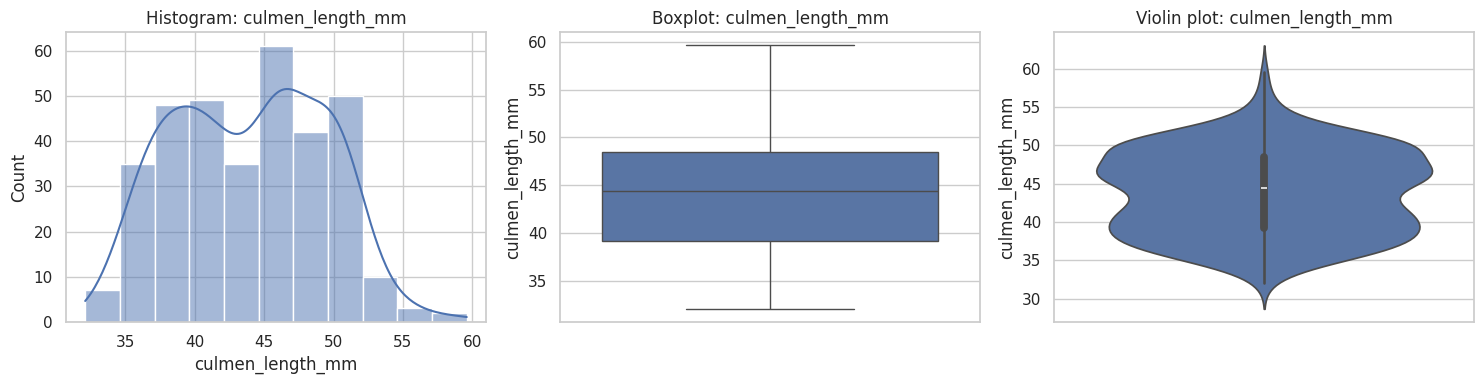

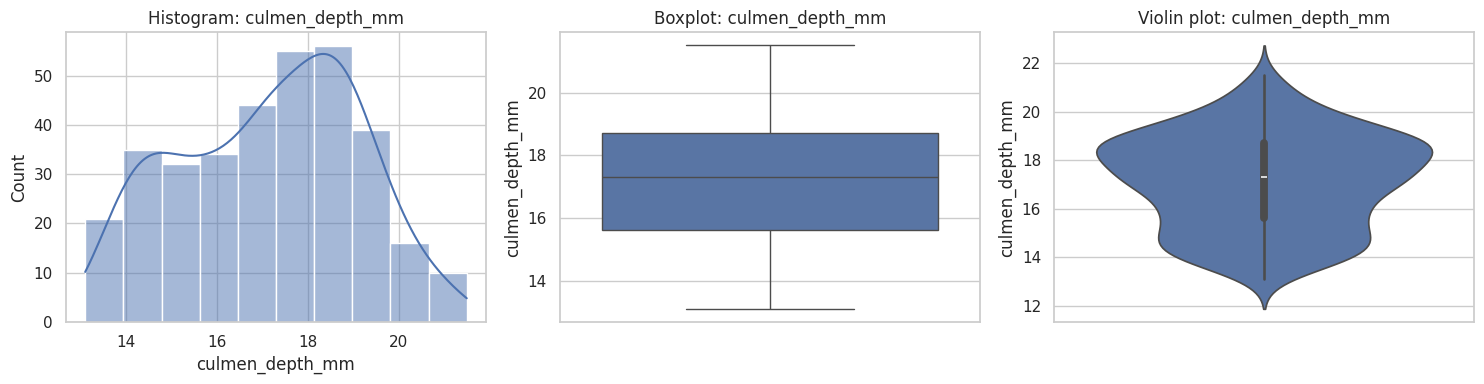

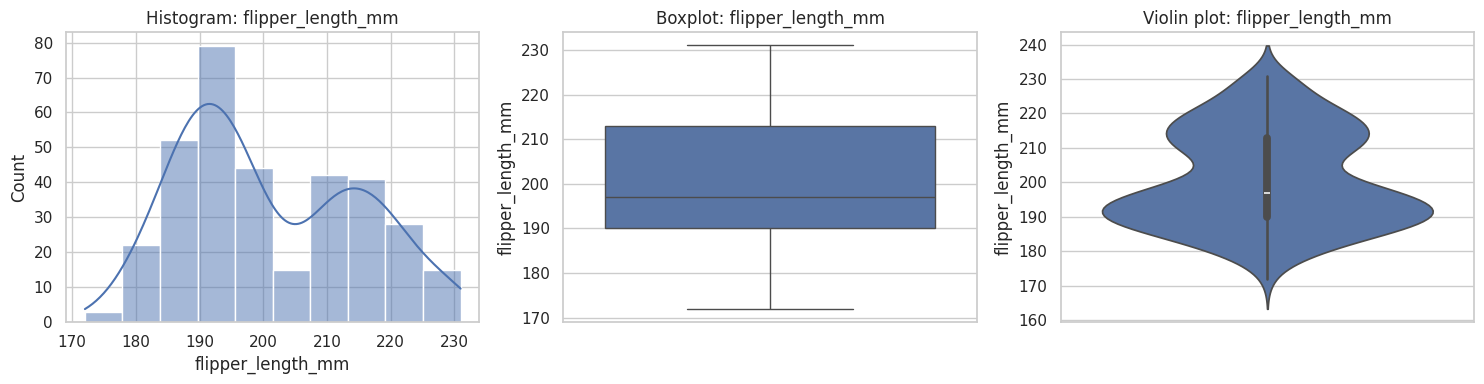

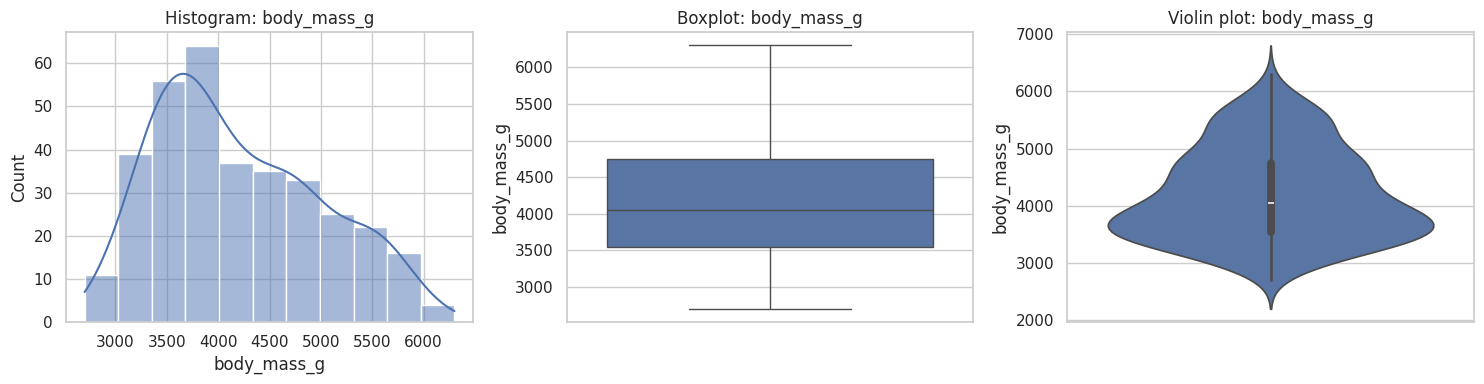

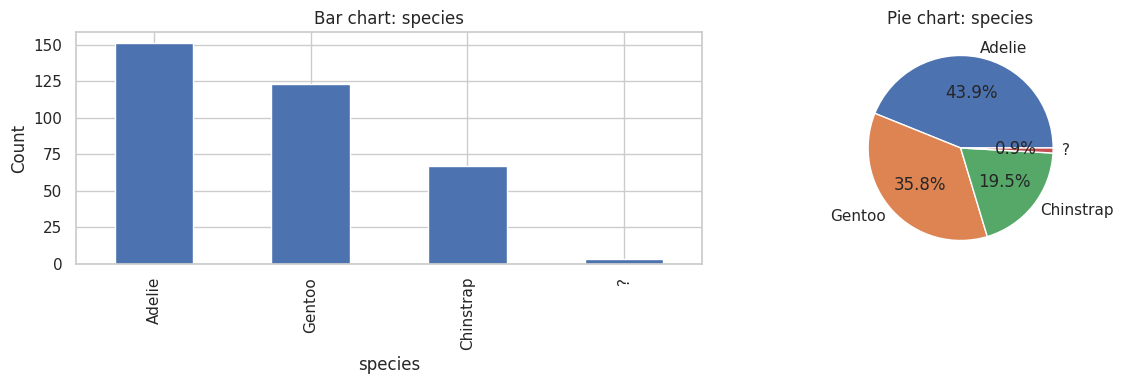

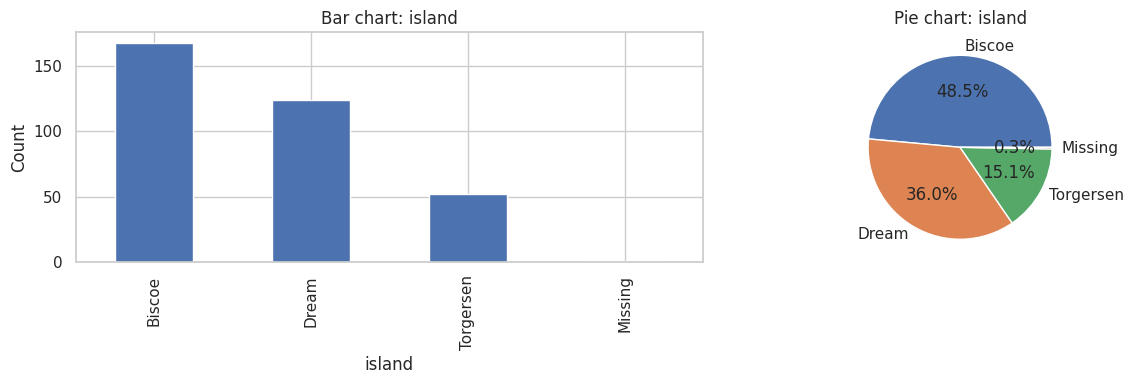

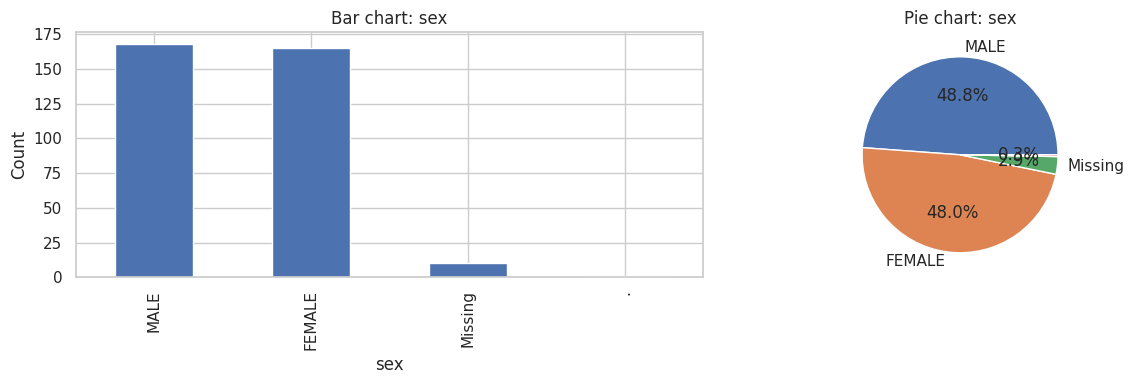

,Variable,Lower bound,Upper bound,Outlier count
0,culmen_length_mm,25.3125,62.4125,0
1,culmen_depth_mm,10.9500,23.3500,0
2,flipper_length_mm,155.5000,247.5000,0
3,body_mass_g,1750.0000,6550.0000,0


In [ ]:
analysis_df = df.drop_duplicates().copy()
numeric_cols = analysis_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = analysis_df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

display(analysis_df.describe(include="all").T)

for col in numeric_cols:
    values = analysis_df[col].dropna()
    if values.empty:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(values, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram: {col}")
    sns.boxplot(y=values, ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")
    sns.violinplot(y=values, ax=axes[2])
    axes[2].set_title(f"Violin plot: {col}")
    plt.tight_layout()
    plt.show()

for col in categorical_cols:
    counts = analysis_df[col].fillna("Missing").value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    counts.plot(kind="bar", ax=axes[0])
    axes[0].set_title(f"Bar chart: {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")
    counts.plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
    axes[1].set_title(f"Pie chart: {col}")
    axes[1].set_ylabel("")
    plt.tight_layout()
    plt.show()

# IQR outlier counts for each numerical variable; this does not remove records.
outlier_rows = []
for col in numeric_cols:
    values = analysis_df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Variable": col,
        "Lower bound": low,
        "Upper bound": high,
        "Outlier count": int(((values < low) | (values > high)).sum())
    })

display(pd.DataFrame(outlier_rows))

## Assessment 4 — Bivariate analysis

island,Biscoe,Dream,Torgersen
species,,,
?,2,1,0
Adelie,43,56,52
Chinstrap,0,67,0
Gentoo,122,0,0


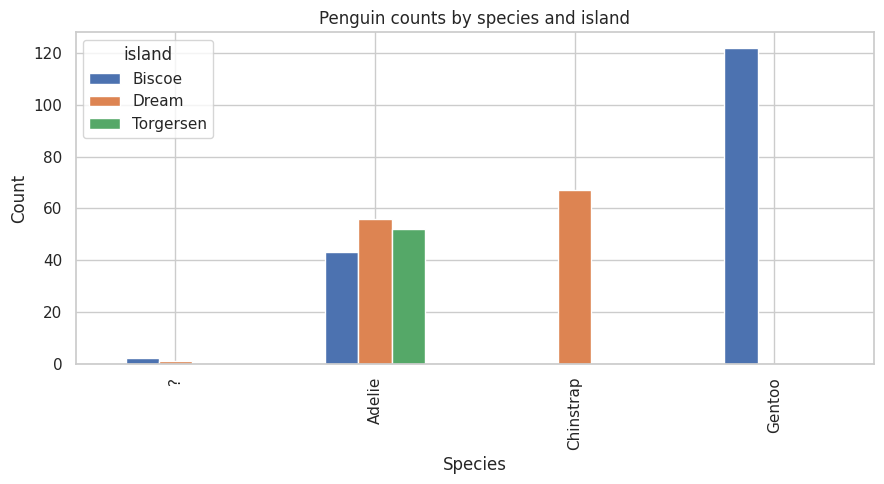

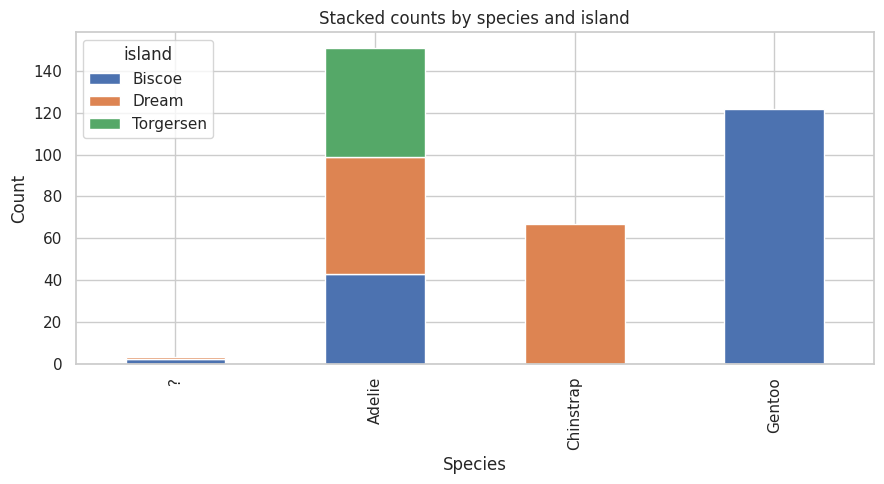

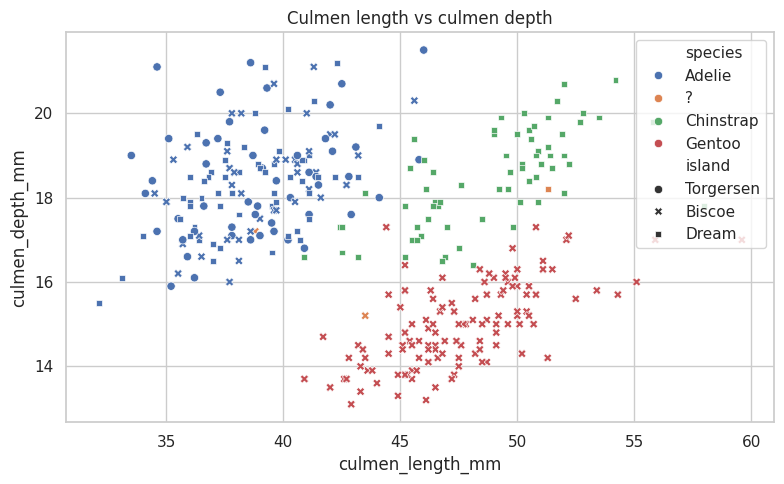

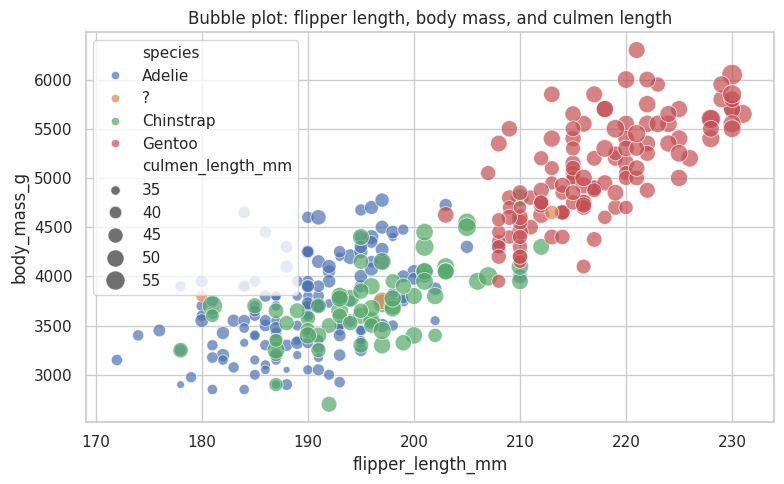

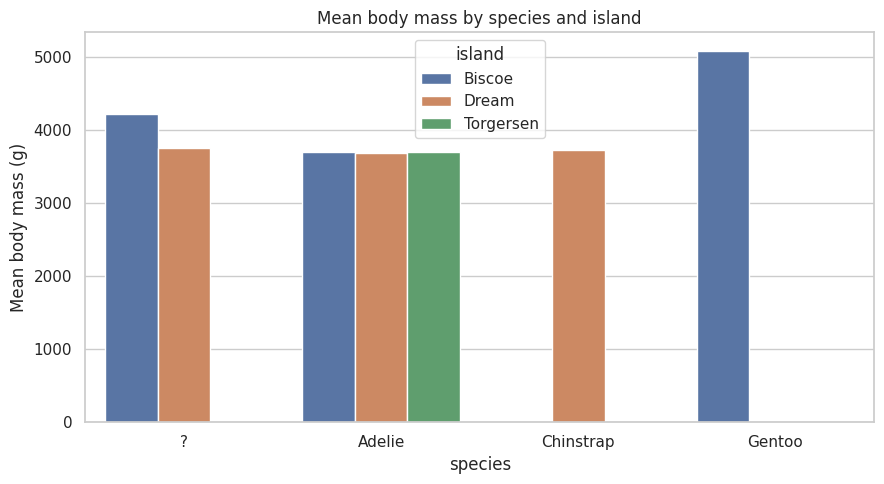

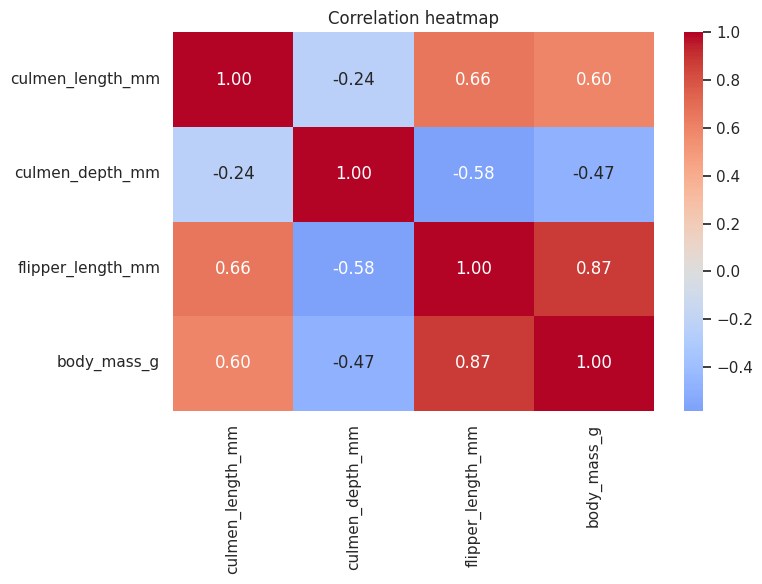

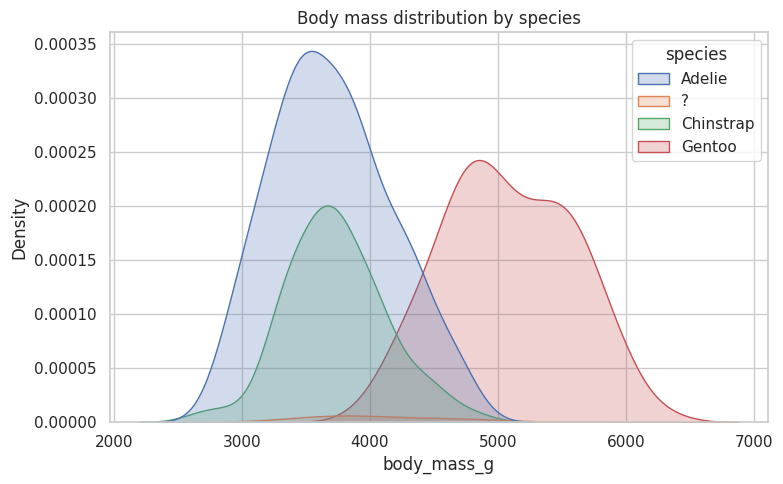

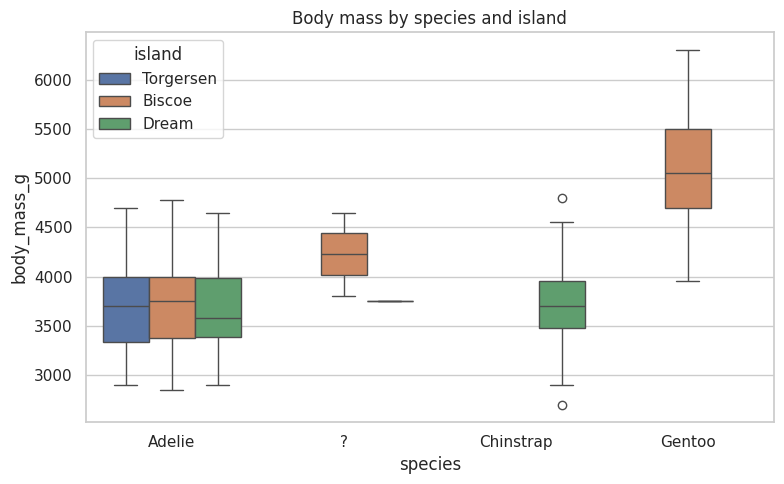

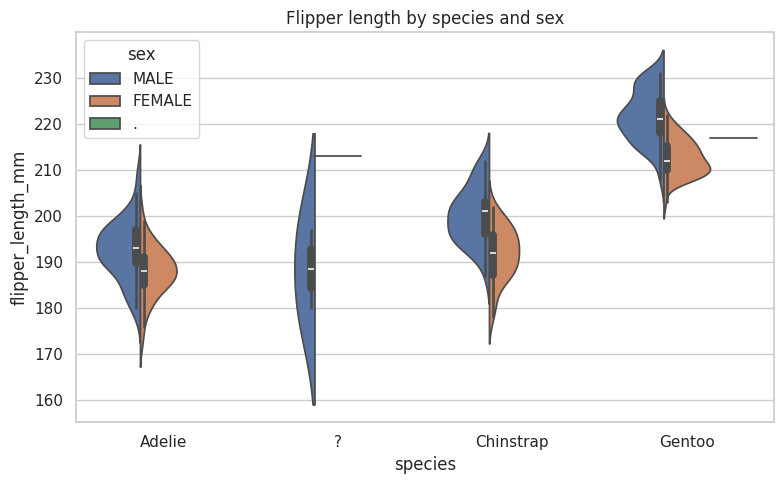

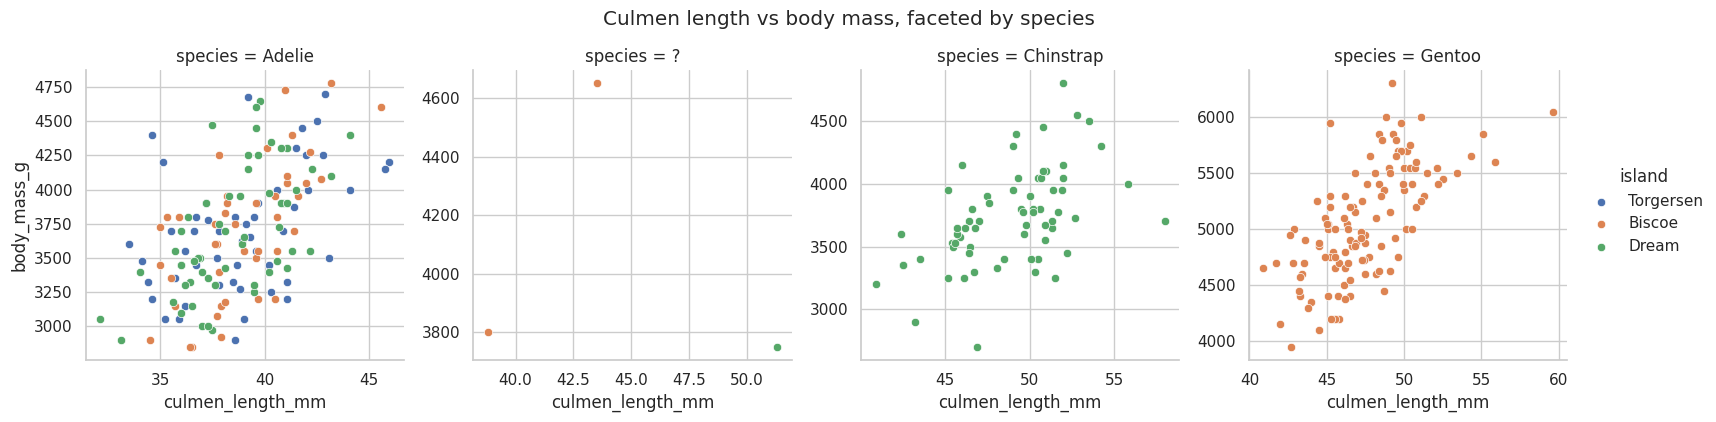

In [ ]:
plot_df = df.copy()
plot_df["body_mass_category"] = pd.cut(
    plot_df["body_mass_g"],
    bins=[0, 3500, 4500, np.inf],
    labels=["Light", "Medium", "Heavy"]
)

# Grouped and stacked bar charts.
counts = pd.crosstab(plot_df["species"], plot_df["island"])
display(counts)

counts.plot(kind="bar", figsize=(9, 5))
plt.title("Penguin counts by species and island")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

counts.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Stacked counts by species and island")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Scatter plot and bubble plot.
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df, x="culmen_length_mm", y="culmen_depth_mm",
    hue="species", style="island"
)
plt.title("Culmen length vs culmen depth")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df, x="flipper_length_mm", y="body_mass_g",
    hue="species", size="culmen_length_mm", sizes=(25, 220), alpha=0.7
)
plt.title("Bubble plot: flipper length, body mass, and culmen length")
plt.tight_layout()
plt.show()

# Grouped mean plot.
mean_mass = plot_df.groupby(["species", "island"], observed=False)["body_mass_g"].mean().reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=mean_mass, x="species", y="body_mass_g", hue="island", errorbar=None)
plt.title("Mean body mass by species and island")
plt.ylabel("Mean body mass (g)")
plt.tight_layout()
plt.show()

# Correlation heatmap.
numeric_cols = plot_df.select_dtypes(include=np.number).columns
corr = plot_df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

# Distribution and group comparisons.
plt.figure(figsize=(8, 5))
sns.kdeplot(data=plot_df, x="body_mass_g", hue="species", fill=True, alpha=0.25)
plt.title("Body mass distribution by species")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x="species", y="body_mass_g", hue="island")
plt.title("Body mass by species and island")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=plot_df, x="species", y="flipper_length_mm", hue="sex", split=True)
plt.title("Flipper length by species and sex")
plt.tight_layout()
plt.show()

# Faceted scatter plots.
g = sns.FacetGrid(plot_df, col="species", hue="island", height=4, sharex=False, sharey=False)
g.map_dataframe(sns.scatterplot, x="culmen_length_mm", y="body_mass_g")
g.add_legend()
g.fig.suptitle("Culmen length vs body mass, faceted by species", y=1.05)
plt.show()

## Assessment 5 — Multivariate analysis

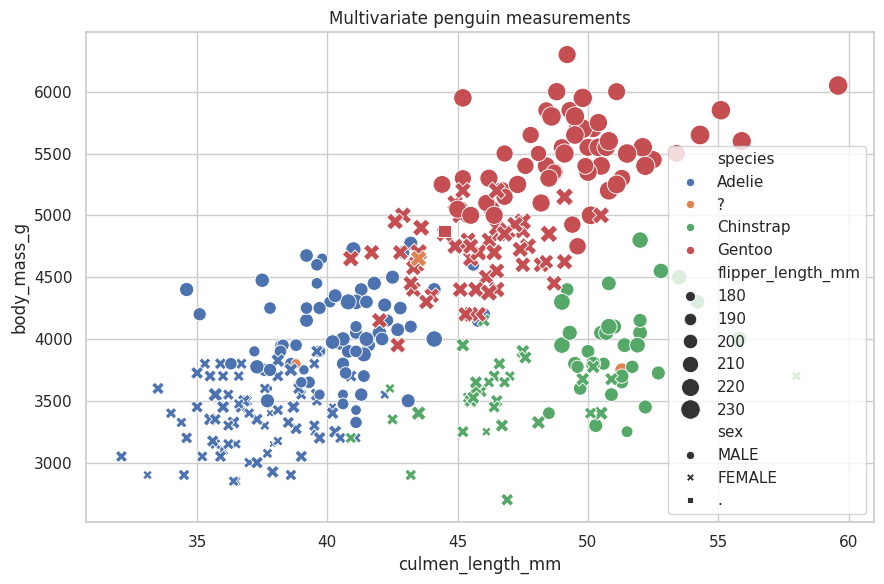

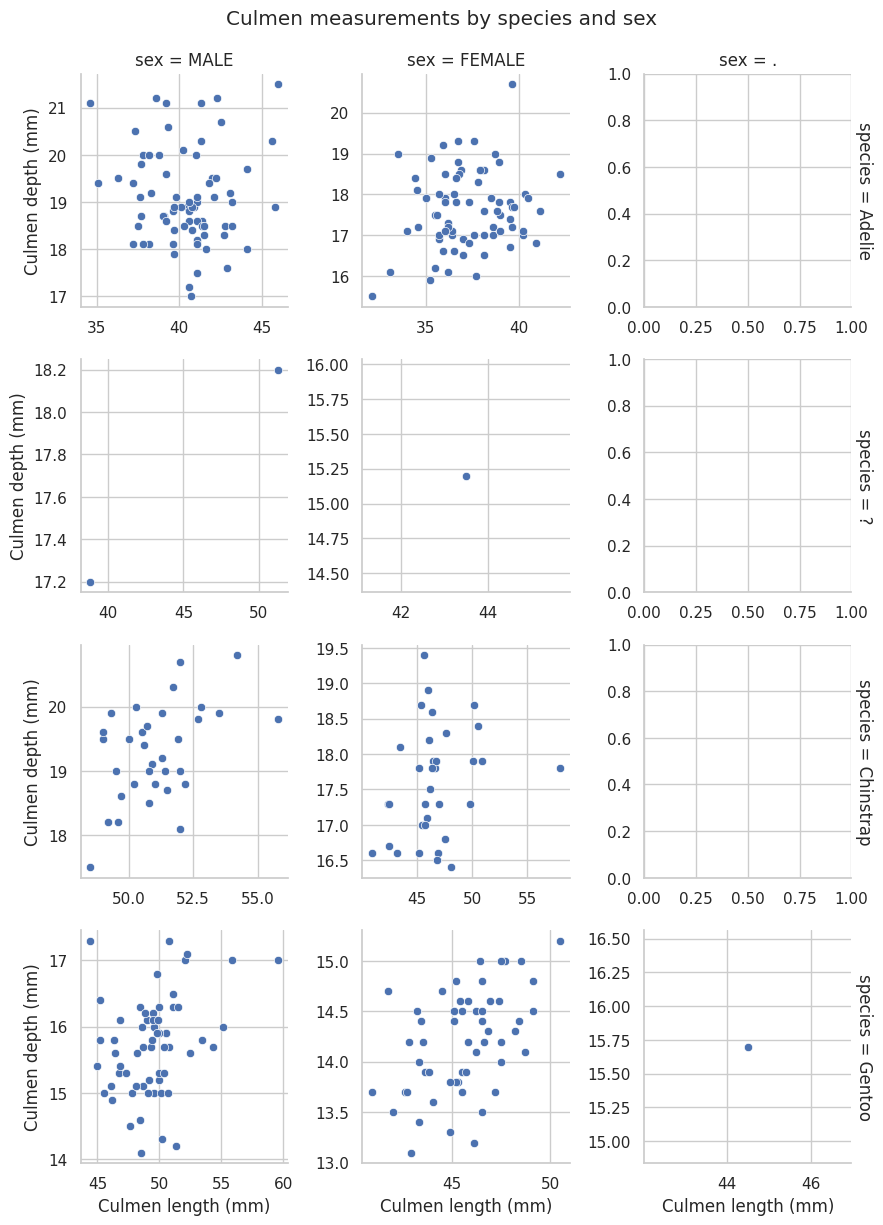

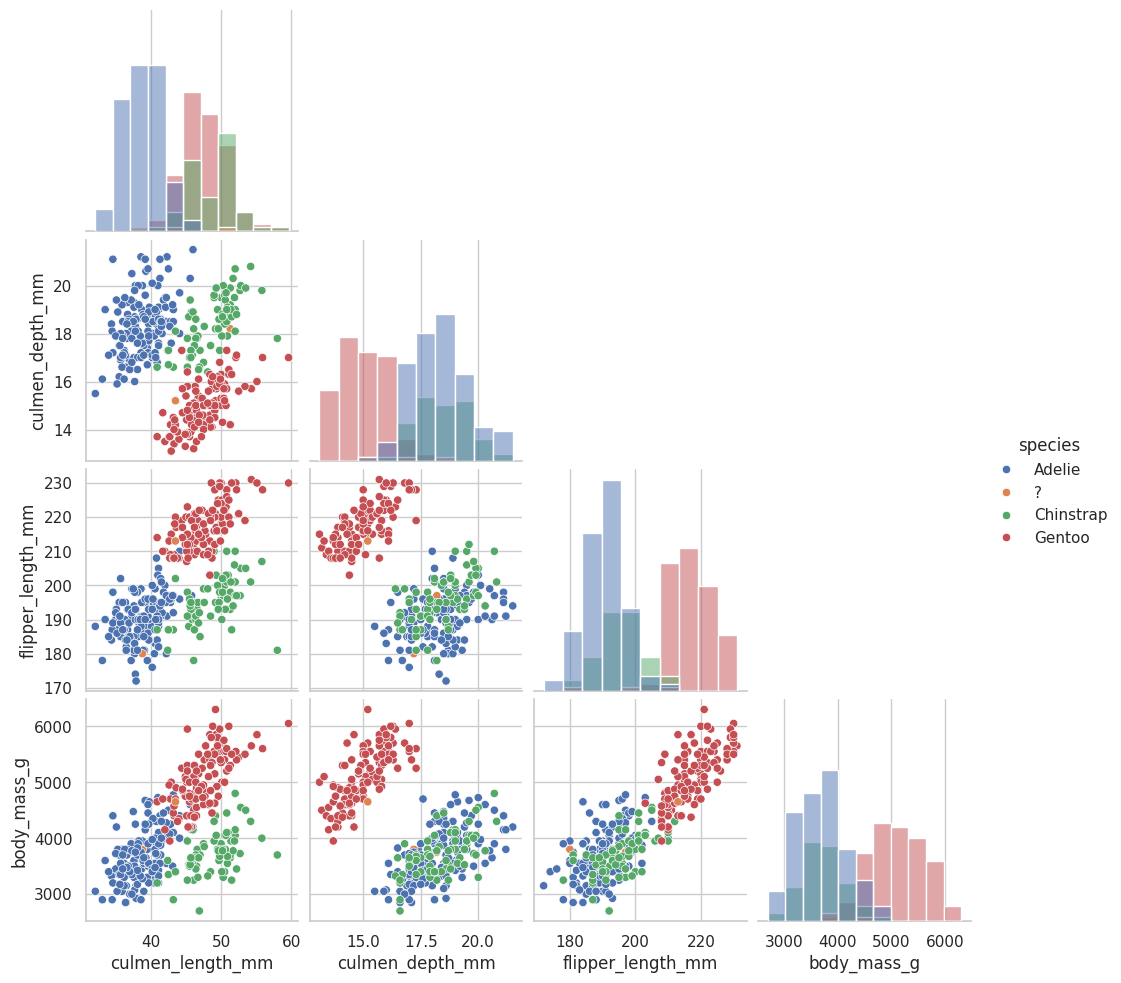

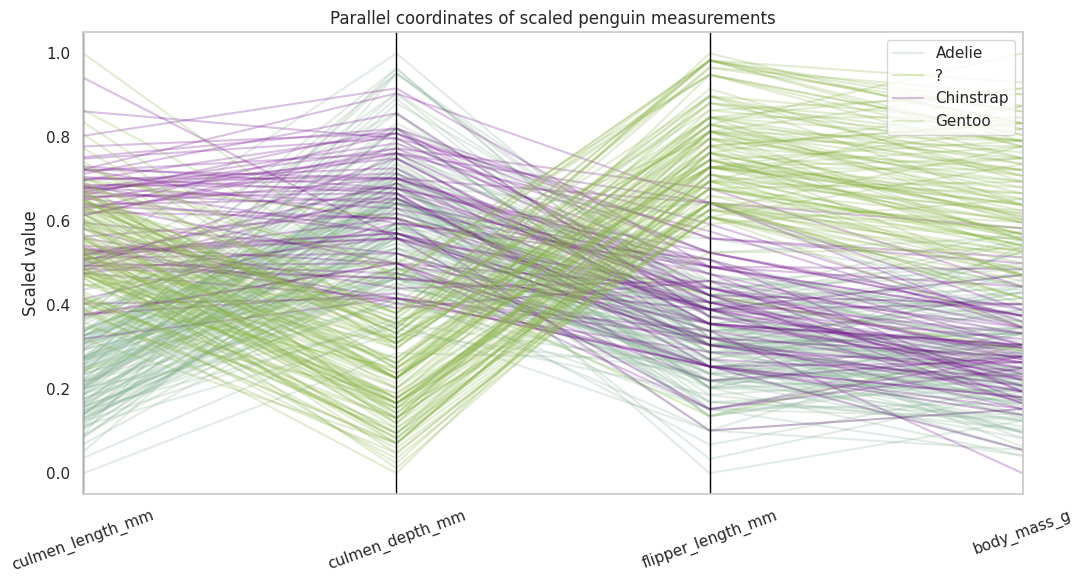

In [ ]:
multi_df = df.dropna(subset=[
    "species", "island", "sex", "culmen_length_mm",
    "culmen_depth_mm", "flipper_length_mm", "body_mass_g"
]).copy()

# Scatter plots with multiple variables encoded.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=multi_df,
    x="culmen_length_mm",
    y="body_mass_g",
    hue="species",
    style="sex",
    size="flipper_length_mm",
    sizes=(30, 200)
)
plt.title("Multivariate penguin measurements")
plt.tight_layout()
plt.show()

# Facet grid by species and sex.
g = sns.FacetGrid(
    multi_df, row="species", col="sex",
    height=3, margin_titles=True, sharex=False, sharey=False
)
g.map_dataframe(sns.scatterplot, x="culmen_length_mm", y="culmen_depth_mm")
g.set_axis_labels("Culmen length (mm)", "Culmen depth (mm)")
g.fig.suptitle("Culmen measurements by species and sex", y=1.02)
plt.show()

# Pair plot of numerical measurements.
pair_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
sns.pairplot(multi_df, vars=pair_cols, hue="species", diag_kind="hist", corner=True)
plt.show()

# Parallel-coordinate plot after min-max scaling.
parallel_df = multi_df[pair_cols + ["species"]].copy()
parallel_df[pair_cols] = MinMaxScaler().fit_transform(parallel_df[pair_cols])
from pandas.plotting import parallel_coordinates
plt.figure(figsize=(11, 6))
parallel_coordinates(parallel_df, class_column="species", alpha=0.25)
plt.title("Parallel coordinates of scaled penguin measurements")
plt.ylabel("Scaled value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Assessment 6 — Time-series analysis limitation and row-order illustration

The penguins_size.csv dataset does not contain a date, year, or timestamp column.
Therefore, a genuine time-series decomposition or ARIMA forecast is not justified for this dataset.
The following plot is only an illustration of record order; row order is not time.


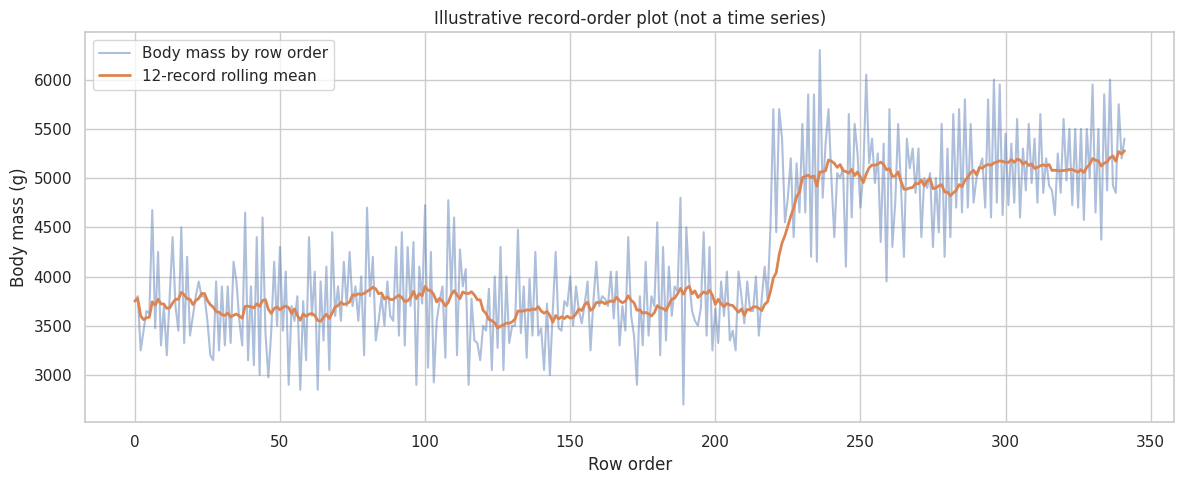

<Figure size 900x400 with 0 Axes>

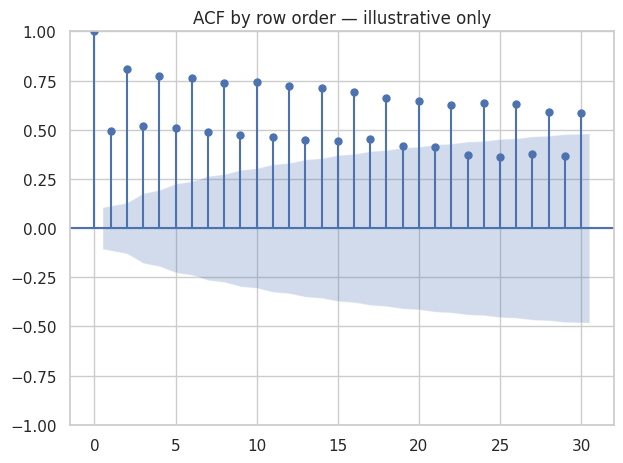

In [ ]:
print("The penguins_size.csv dataset does not contain a date, year, or timestamp column.")
print("Therefore, a genuine time-series decomposition or ARIMA forecast is not justified for this dataset.")
print("The following plot is only an illustration of record order; row order is not time.")

measurement = df["body_mass_g"].dropna().reset_index(drop=True)
rolling_mean = measurement.rolling(window=12, min_periods=1).mean()

plt.figure(figsize=(12, 5))
plt.plot(measurement.index, measurement, alpha=0.45, label="Body mass by row order")
plt.plot(rolling_mean.index, rolling_mean, linewidth=2, label="12-record rolling mean")
plt.title("Illustrative record-order plot (not a time series)")
plt.xlabel("Row order")
plt.ylabel("Body mass (g)")
plt.legend()
plt.tight_layout()
plt.show()

# Autocorrelation here is order-dependent and should not be interpreted as temporal evidence.
try:
    from statsmodels.graphics.tsaplots import plot_acf
    plt.figure(figsize=(9, 4))
    plot_acf(measurement, lags=30)
    plt.title("ACF by row order — illustrative only")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Optional ACF plot skipped. Install statsmodels with %pip install statsmodels if required.")

## Assessment 7 — Descriptive statistics and grouped summaries

,Mean,Median,Minimum,Maximum,Range,Variance,Standard deviation,IQR,Skewness,Kurtosis
culmen_length_mm,43.922,44.45,32.1,59.6,27.5,29.807,5.460,9.275,0.053,-0.876
culmen_depth_mm,17.151,17.30,13.1,21.5,8.4,3.900,1.975,3.100,-0.143,-0.907
flipper_length_mm,200.874,197.00,172.0,231.0,59.0,197.728,14.062,23.000,0.353,-0.977
body_mass_g,4201.754,4050.00,2700.0,6300.0,3600.0,643131.077,801.955,1200.000,0.470,-0.719


Species frequency:


,Count
species,
Adelie,151
Gentoo,123
Chinstrap,67
?,3


Island frequency:


,Count
island,
Biscoe,167
Dream,124
Torgersen,52
NaN,1


Sex frequency:


... (4 outputs left out)

culmen_length_mm                     culmen_depth_mm                \
                     count   mean median   std           count   mean median   
species                                                                        
?                        3  44.53   43.5  6.31               3  16.87   17.2   
Adelie                 150  38.79   38.8  2.67             150  18.35   18.4   
Chinstrap               67  48.80   49.5  3.35              67  18.42   18.5   
Gentoo                 122  47.54   47.3  3.07             122  14.98   15.0   

                flipper_length_mm                       body_mass_g           \
            std             count    mean median    std       count     mean   
species                                                                        
?          1.53                 3  196.67  197.0  16.50           3  4066.67   
Adelie     1.22               150  190.02  190.0   6.51         150  3700.00   
Chinstrap  1.14                67  195.81  196.0   7.18          67  3732.84   
Gentoo     0.99               121  217.24  216.0   6.52         122  5079.51   

                           
           median     std  
species                    
?          3800.0  505.80  
Adelie     3700.0  460.03  
Chinstrap  3700.0  387.23  
Gentoo     5025.0  504.70

Species and sex grouped body-mass statistics:


count     mean  median     std
species   sex                                   
?         FEMALE      1  4650.00  4650.0     NaN
          MALE        2  3775.00  3775.0   35.36
Adelie    FEMALE     73  3368.84  3400.0  269.38
          MALE       72  4046.88  4000.0  348.03
Chinstrap FEMALE     34  3527.21  3550.0  285.33
          MALE       33  3944.70  3950.0  366.19
Gentoo    .           1  4875.00  4875.0     NaN
          FEMALE     57  4680.26  4700.0  284.05
          MALE       61  5484.84  5500.0  313.16

Pearson correlation: PearsonRResult(statistic=np.float64(0.8708366769817716), pvalue=np.float64(1.3942969635169552e-106))
Spearman correlation: SignificanceResult(statistic=np.float64(0.8389212459629661), pvalue=np.float64(1.4083166162663432e-91))


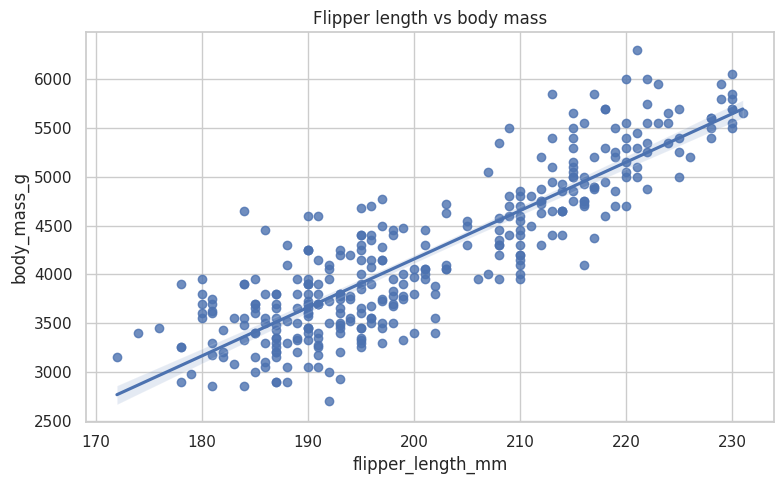

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

stats_table = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Minimum": df[numeric_cols].min(),
    "Maximum": df[numeric_cols].max(),
    "Range": df[numeric_cols].max() - df[numeric_cols].min(),
    "Variance": df[numeric_cols].var(),
    "Standard deviation": df[numeric_cols].std(),
    "IQR": df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurtosis()
})
display(stats_table.round(3))

print("Species frequency:")
display(df["species"].value_counts(dropna=False).to_frame("Count"))
print("Island frequency:")
display(df["island"].value_counts(dropna=False).to_frame("Count"))
print("Sex frequency:")
display(df["sex"].value_counts(dropna=False).to_frame("Count"))

print("Species and island contingency table:")
display(pd.crosstab(df["species"], df["island"], margins=True))

print("Grouped measurement summaries:")
grouped_summary = df.groupby("species", observed=False)[numeric_cols].agg(["count", "mean", "median", "std"])
display(grouped_summary.round(2))

print("Species and sex grouped body-mass statistics:")
display(
    df.groupby(["species", "sex"], observed=False)["body_mass_g"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

# Pearson and Spearman correlations for selected numeric variables.
from scipy.stats import pearsonr, spearmanr
corr_data = df[["flipper_length_mm", "body_mass_g"]].dropna()
if len(corr_data) >= 3:
    print("Pearson correlation:", pearsonr(corr_data["flipper_length_mm"], corr_data["body_mass_g"]))
    print("Spearman correlation:", spearmanr(corr_data["flipper_length_mm"], corr_data["body_mass_g"]))

plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="flipper_length_mm", y="body_mass_g")
plt.title("Flipper length vs body mass")
plt.tight_layout()
plt.show()

## Assessment 8 — Clustering (K-means and hierarchical)

K-means (2 clusters) sizes:


,Count
1,122
2,219


Cluster centers in standardized units:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,0.658836,-1.104108,1.163099,1.095523
1,-0.367023,0.615074,-0.647936,-0.610291


Within-cluster sum of squares: 564.9967272063457


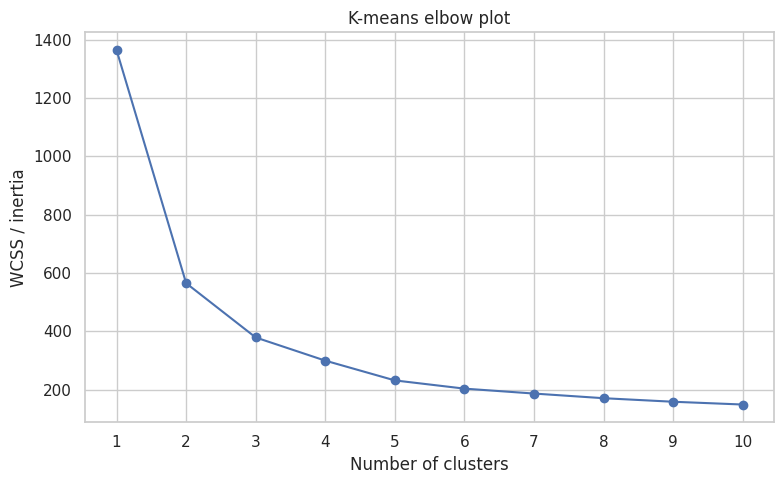

K-means (3 clusters) sizes:


,Count
KMeans_Cluster,
1,87
2,122
3,132


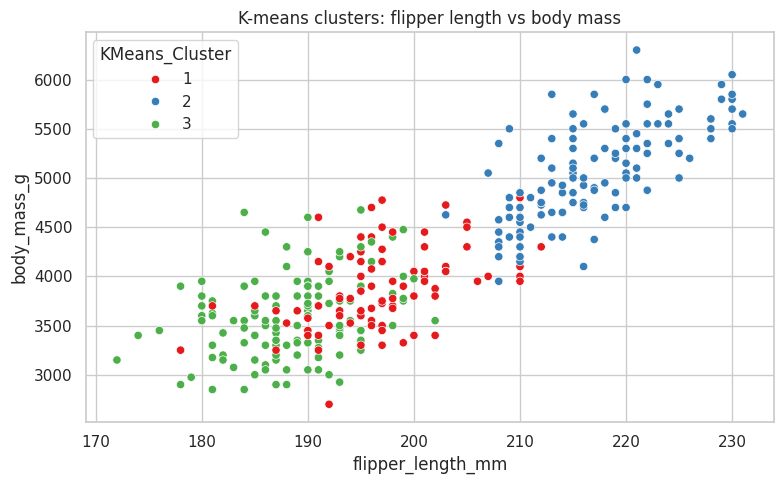

Number of pairwise distances: 57970


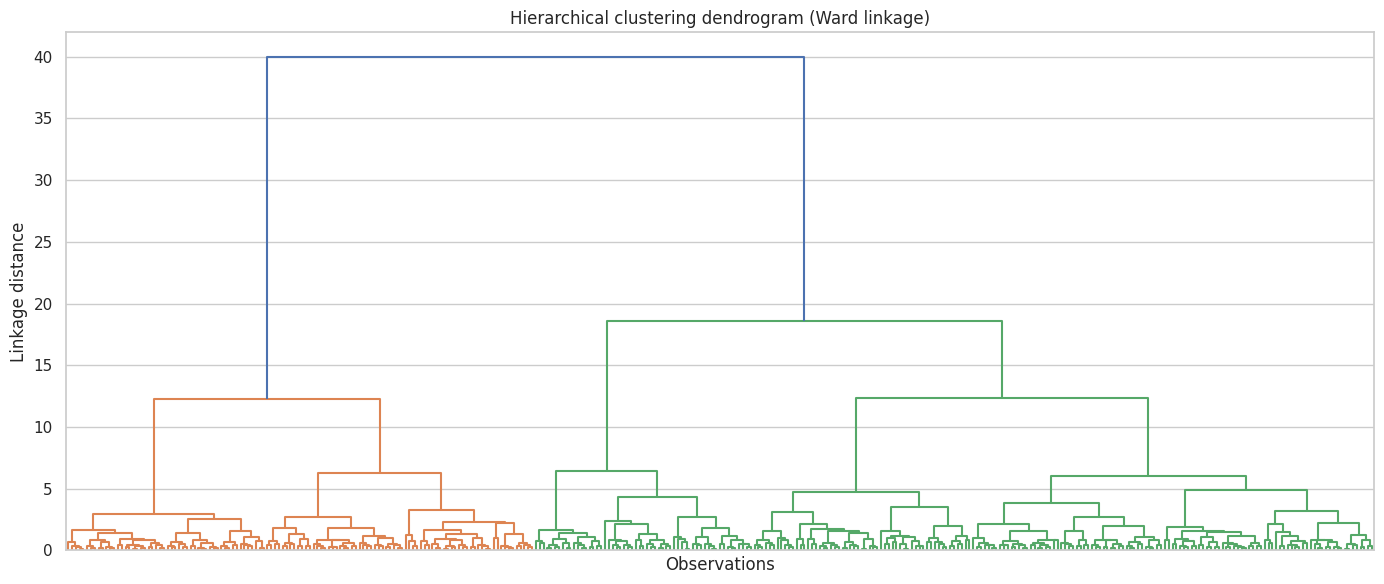

Hierarchical cluster sizes:


,Count
Hierarchical_Cluster,
1,122
2,57
3,162


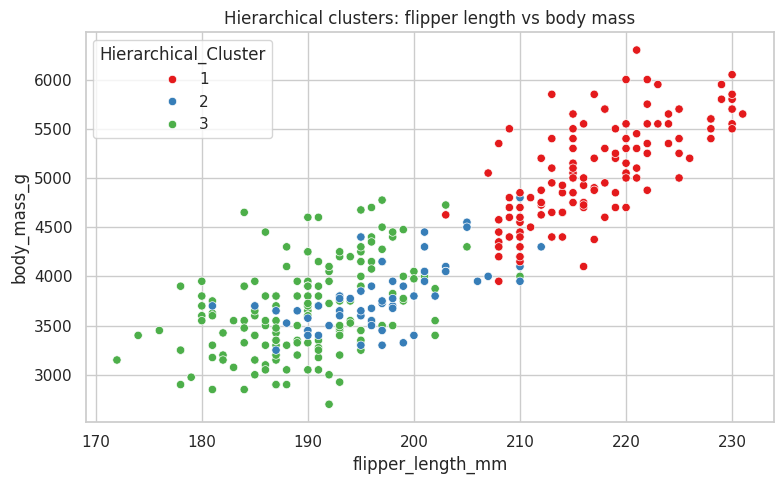

In [ ]:
cluster_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
cluster_df = df[cluster_cols].dropna().copy()
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_df)

# K-means with 2 clusters.
kmeans2 = KMeans(n_clusters=2, n_init=25, random_state=123)
labels2 = kmeans2.fit_predict(cluster_scaled)
print("K-means (2 clusters) sizes:")
display(pd.Series(labels2 + 1).value_counts().sort_index().to_frame("Count"))
print("Cluster centers in standardized units:")
display(pd.DataFrame(kmeans2.cluster_centers_, columns=cluster_cols))
print("Within-cluster sum of squares:", kmeans2.inertia_)

# Elbow method.
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=123)
    model.fit(cluster_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS / inertia")
plt.title("K-means elbow plot")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

# Three-cluster solution.
kmeans3 = KMeans(n_clusters=3, n_init=25, random_state=123)
labels3 = kmeans3.fit_predict(cluster_scaled)
cluster_results = cluster_df.copy()
cluster_results["KMeans_Cluster"] = labels3 + 1
print("K-means (3 clusters) sizes:")
display(cluster_results["KMeans_Cluster"].value_counts().sort_index().to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=cluster_results,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="KMeans_Cluster",
    palette="Set1"
)
plt.title("K-means clusters: flipper length vs body mass")
plt.tight_layout()
plt.show()

# Hierarchical clustering using Ward linkage.
distances = pdist(cluster_scaled, metric="euclidean")
print("Number of pairwise distances:", len(distances))
hierarchy = linkage(cluster_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(hierarchy, no_labels=True)
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.xlabel("Observations")
plt.ylabel("Linkage distance")
plt.tight_layout()
plt.show()

hier_labels = fcluster(hierarchy, t=3, criterion="maxclust")
hier_results = cluster_df.copy()
hier_results["Hierarchical_Cluster"] = hier_labels
print("Hierarchical cluster sizes:")
display(hier_results["Hierarchical_Cluster"].value_counts().sort_index().to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=hier_results,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="Hierarchical_Cluster",
    palette="Set1"
)
plt.title("Hierarchical clusters: flipper length vs body mass")
plt.tight_layout()
plt.show()

## Assessment 9 — Principal Component Analysis (PCA)

,Principal Component,Eigenvalue,Variance explained (%),Cumulative variance (%)
0,PC1,2.760,68.790,68.790
1,PC2,0.776,19.342,88.132
2,PC3,0.367,9.148,97.280
3,PC4,0.109,2.720,100.000


Principal component loadings:


,PC1,PC2,PC3,PC4
culmen_length_mm,0.455,0.596,0.645,-0.146
culmen_depth_mm,-0.400,0.798,-0.418,0.168
flipper_length_mm,0.576,0.002,-0.232,0.784
body_mass_g,0.548,0.085,-0.596,-0.580


Components required to explain at least 80% variance: 2


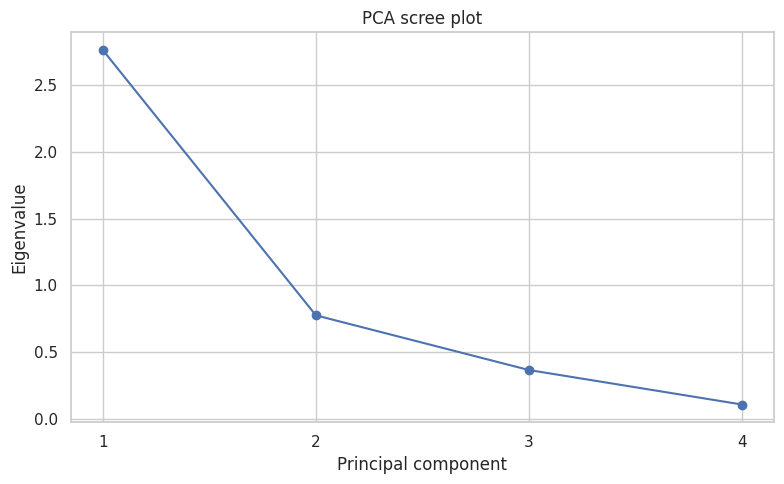

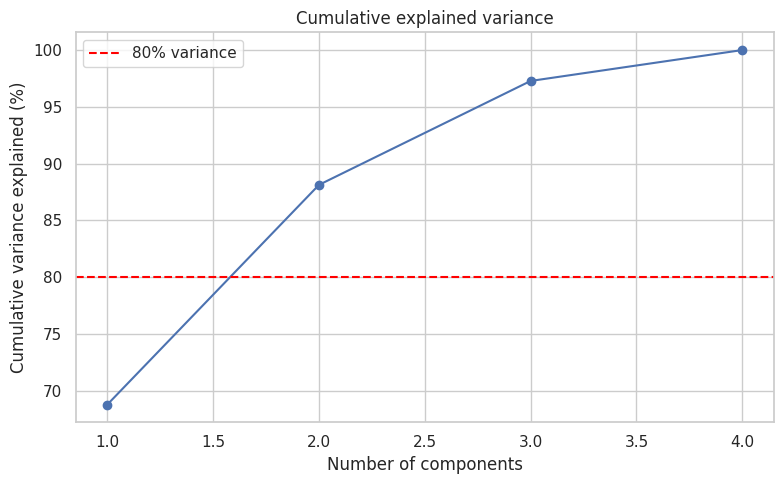

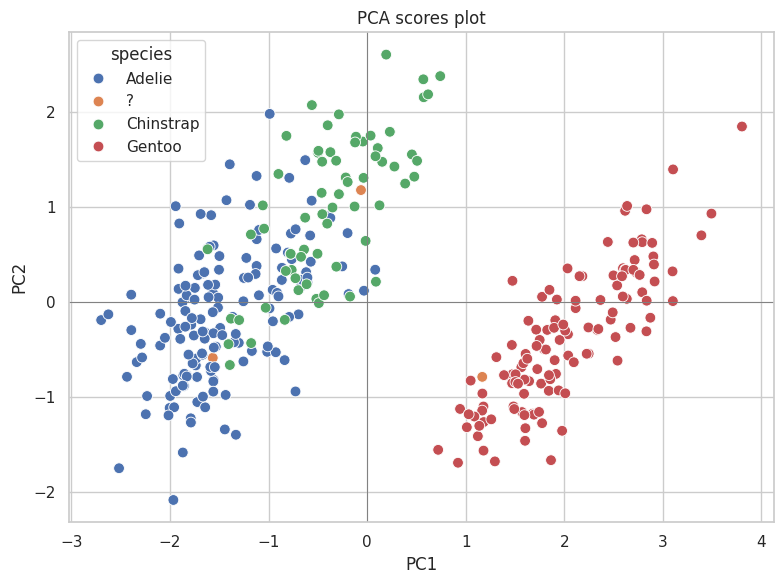

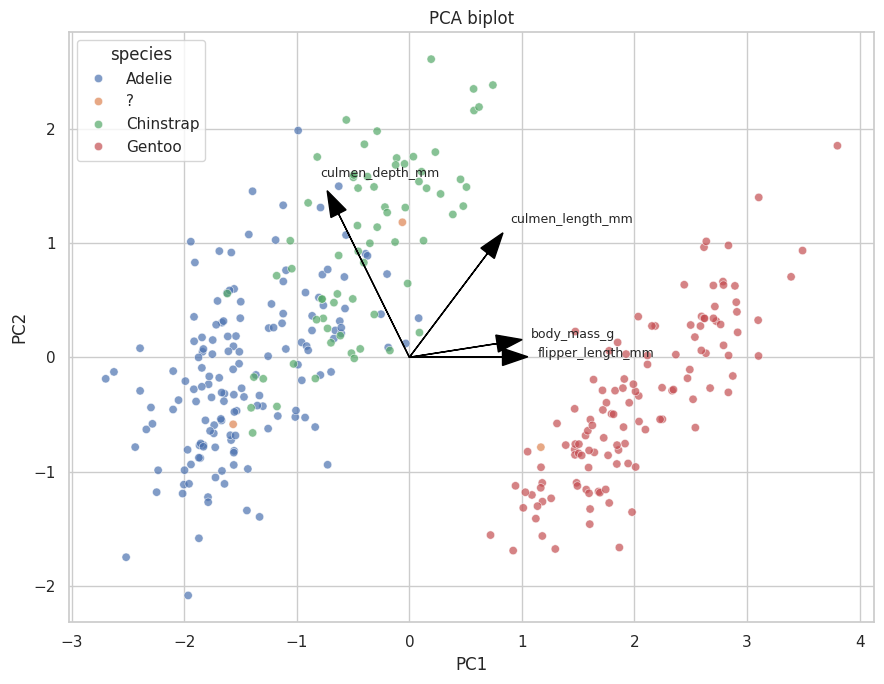

In [ ]:
pca_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
pca_data = df[pca_cols].dropna().copy()

pca_scaler = StandardScaler()
pca_scaled = pca_scaler.fit_transform(pca_data)

pca_model = PCA()
pca_scores = pca_model.fit_transform(pca_scaled)

explained = pca_model.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(explained))],
    "Eigenvalue": pca_model.explained_variance_,
    "Variance explained (%)": explained,
    "Cumulative variance (%)": cumulative
})
display(variance_table.round(3))

loadings = pd.DataFrame(
    pca_model.components_.T,
    index=pca_cols,
    columns=[f"PC{i+1}" for i in range(len(pca_cols))]
)
print("Principal component loadings:")
display(loadings.round(3))

n80 = int(np.argmax(cumulative >= 80) + 1) if np.any(cumulative >= 80) else len(cumulative)
print("Components required to explain at least 80% variance:", n80)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), pca_model.explained_variance_, marker="o")
plt.xlabel("Principal component")
plt.ylabel("Eigenvalue")
plt.title("PCA scree plot")
plt.xticks(range(1, len(explained) + 1))
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), cumulative, marker="o")
plt.axhline(80, linestyle="--", color="red", label="80% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance explained (%)")
plt.title("Cumulative explained variance")
plt.legend()
plt.tight_layout()
plt.show()

score_df = pd.DataFrame(pca_scores[:, :2], columns=["PC1", "PC2"], index=pca_data.index)
score_df = score_df.join(df.loc[pca_data.index, ["species"]])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=score_df, x="PC1", y="PC2", hue="species", s=60)
plt.axhline(0, color="gray", linewidth=0.7)
plt.axvline(0, color="gray", linewidth=0.7)
plt.title("PCA scores plot")
plt.tight_layout()
plt.show()

# Biplot: scores plus scaled loading arrows.
plt.figure(figsize=(9, 7))
sns.scatterplot(data=score_df, x="PC1", y="PC2", hue="species", alpha=0.7)
arrow_scale = min(score_df["PC1"].abs().max(), score_df["PC2"].abs().max()) * 0.7
for feature in pca_cols:
    x_loading = loadings.loc[feature, "PC1"] * arrow_scale
    y_loading = loadings.loc[feature, "PC2"] * arrow_scale
    plt.arrow(0, 0, x_loading, y_loading, color="black", head_width=0.15, length_includes_head=True)
    plt.text(x_loading * 1.08, y_loading * 1.08, feature, fontsize=9)
plt.title("PCA biplot")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()